# Radiomics Classification Pipeline
**EGD_COD** | Targets: IDH · Merged (1p19q LGG)

Flow: Load → StandardScale → `UniqueThenTopK` feature selection → XGBoost CV + test → SHAP top-10 → ANFIS (GMM) CV + test → BN (HC+BIC & TAN) CV + test

In [2]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import networkx as nx
import re

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import f_classif, VarianceThreshold
from sklearn.linear_model import LassoCV, Lasso
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, brier_score_loss,
    average_precision_score, confusion_matrix, roc_curve
)
from sklearn.mixture import GaussianMixture
from sklearn.feature_selection import mutual_info_classif

import xgboost as xgb
from xgboost import XGBClassifier, DMatrix

import torch, torch.nn as nn

from pgmpy.models import BayesianNetwork
from pgmpy.estimators import HillClimbSearch, BicScore, BayesianEstimator
from pgmpy.inference import VariableElimination

from get_data import get_data

# ── Global config ─────────────────────────────────────────────────────────────
RANDOM_STATE  = 24
TEST_SIZE     = 0.15
N_SPLITS      = 10
TOP_K_SHAP    = 10      # SHAP features passed to ANFIS & BN
K_RULES       = 10      # GMM components / fuzzy rules
N_BINS        = 5       # KBins for BN discretisation
K_PER_GROUP   = 10      # features kept per radiomics class group
SELECTOR      = 'anova' # 'anova' | 'lasso' | 'lasso_topk'  ← choose here
N_ESTIMATORS  = 1000


## 1 · Data

In [3]:
train_df, test_df = get_data('EGD_COD', TEST_SIZE, RANDOM_STATE)

def _Xy(df, target):
    m = df[target] != -1
    return (df.loc[m].iloc[:, :-4].reset_index(drop=True),
            df.loc[m, target].reset_index(drop=True))

def _Xy_merged(df):
    m = (df['IDH']==1) & (df['Label']!=-1) & (df['Grade']<4)
    return (df.loc[m].iloc[:, :-4].reset_index(drop=True),
            df.loc[m, 'Label'].reset_index(drop=True))

Xtr_idh,  ytr_idh  = _Xy(train_df, 'IDH')
Xte_idh,  yte_idh  = _Xy(test_df,  'IDH')
Xtr_mrg,  ytr_mrg  = _Xy_merged(train_df)
Xte_mrg,  yte_mrg  = _Xy_merged(test_df)

# StandardScale — fit on train only
def _scale(Xtr, Xte):
    sc = StandardScaler()
    return (pd.DataFrame(sc.fit_transform(Xtr), columns=Xtr.columns),
            pd.DataFrame(sc.transform(Xte),     columns=Xte.columns))

Xtr_idh, Xte_idh = _scale(Xtr_idh, Xte_idh)
Xtr_mrg, Xte_mrg = _scale(Xtr_mrg, Xte_mrg)

print(f"IDH    train {Xtr_idh.shape}  test {Xte_idh.shape}  pos={ytr_idh.mean():.2f}")
print(f"Merged train {Xtr_mrg.shape}  test {Xte_mrg.shape}  pos={ytr_mrg.mean():.2f}")
print(f"Features: {Xtr_idh.shape[1]}")


EGD: total 1p19q = 259 | 1p19q+ = 73 | pos rate = 0.282
EGD: total idh = 467 | idh+ = 155 | pos rate = 0.332
IDH    train (399, 20216)  test (68, 20216)  pos=0.34
Merged train (131, 20216)  test (18, 20216)  pos=0.47
Features: 20216


In [4]:
full_df = pd.concat([train_df, test_df], ignore_index=True)

cohorts = {
    "IDH": full_df[full_df["IDH"] != -1],
    "1p19q": full_df[
        (full_df["IDH"] == 1)
        & (full_df["Label"] != -1)
        & (full_df["Grade"] < 4)
    ],
}

for name, df in cohorts.items():
    age = pd.to_numeric(df["Age"], errors="coerce")
    age = age[age >= 0]

    print(f"\n{name}")
    print(f"N = {len(df)}")
    print(
        f"Age: mean={age.mean():.2f}, SD={age.std():.2f}, "
        f"median={age.median():.2f}, "
        f"IQR=({age.quantile(.25):.2f}, {age.quantile(.75):.2f}), "
        f"range=({age.min():.2f}, {age.max():.2f})"
    )
    print("Sex:")
    print(df["Sex"].value_counts(dropna=False))


IDH
N = 467
Age: mean=55.82, SD=14.43, median=55.41, IQR=(47.00, 68.00), range=(19.00, 86.00)
Sex:
Sex
1    292
0    175
Name: count, dtype: int64

1p19q
N = 149
Age: mean=43.17, SD=11.99, median=43.00, IQR=(35.00, 52.00), range=(21.00, 75.00)
Sex:
Sex
1    93
0    56
Name: count, dtype: int64


In [5]:
print(full_df["Sex"].value_counts(dropna=False))

Sex
1    304
0    179
Name: count, dtype: int64


## 2 · Feature Selection

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# Feature Selectors  (choose via  SELECTOR  in the config cell)
#
#  'anova'     → UniqueThenTopK        – ANOVA score, collapse contrasts, top-k
#  'lasso'     → GroupedCoeThrLasso    – ANOVA pre-filter → LassoCV → coef-thr
#  'lasso_topk'→ UniqueThenTopKLasso   – ANOVA → collapse → LassoCV → top-k
# ══════════════════════════════════════════════════════════════════════════════

CLASS_SET = {"firstorder","shape","glcm","glrlm","glszm","gldm","ngtdm"}

# ── helpers shared by all selectors ──────────────────────────────────────────
def _parse_meta(columns):
    rows = []
    for name in [str(c) for c in columns]:
        contrast, rest = name.split("_",1) if "_" in name else ("UNK", name)
        cls = next((t for t in rest.split("_") if t.lower() in CLASS_SET), "UNK")
        rows.append(dict(name=name, contrast=contrast, base_id=rest, cls=cls))
    return pd.DataFrame(rows)

def _safe_scores(X, y):
    var = np.nanstd(X, axis=0); nonconst = var > 0
    scores = np.zeros(X.shape[1], dtype=float)
    if nonconst.any():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            out = f_classif(X[:, nonconst], y)
        s = out[0] if isinstance(out, (tuple,list)) else out
        scores[nonconst] = np.nan_to_num(s)
    return scores

def _ak_mask(columns, always_keep):
    return np.array([c in always_keep for c in [str(c) for c in columns]], dtype=bool)


# ── Selector 1: UniqueThenTopK (ANOVA) ───────────────────────────────────────
class UniqueThenTopK(BaseEstimator, TransformerMixin):
    """ANOVA score → collapse duplicate contrasts → top-k per radiomics class."""
    def __init__(self, k_per_group=20, groupby="class",
                 always_keep=("Age","Sex"), max_total=None):
        self.k_per_group = k_per_group
        self.groupby     = groupby
        self.always_keep = set(always_keep)
        self.max_total   = max_total

    def fit(self, X, y):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        self.columns_ = list(X.columns)
        ak  = _ak_mask(self.columns_, self.always_keep)
        ak_idx = np.where(ak)[0]

        work_cols = [c for c, a in zip(self.columns_, ak) if not a]
        meta = _parse_meta(work_cols)
        meta["score"] = _safe_scores(X[work_cols].values, y)

        # collapse contrasts
        uniq = meta.groupby("base_id")["score"].idxmax().values
        meta_u = meta.loc[uniq].copy()

        # group label
        if self.groupby == "class":           meta_u["group"] = meta_u["cls"]
        elif self.groupby == "contrast":      meta_u["group"] = meta_u["contrast"]
        elif self.groupby == "class_contrast":meta_u["group"] = meta_u["cls"]+"|"+meta_u["contrast"]
        else: raise ValueError("groupby must be 'class'|'contrast'|'class_contrast'")

        keep = []
        for _, sub in meta_u.groupby("group"):
            k = min(self.k_per_group, len(sub))
            keep.extend(sub.nlargest(k, "score").index.tolist())

        if self.max_total is not None and len(keep) + len(ak_idx) > self.max_total:
            keep = meta.loc[keep].nlargest(self.max_total - len(ak_idx), "score").index.tolist()

        final = np.zeros(len(self.columns_), bool)
        final[ak_idx] = True
        for idx in keep:
            final[self.columns_.index(meta.loc[idx, "name"])] = True

        self.selected_features_ = [c for c, f in zip(self.columns_, final) if f]
        self.selected_mask_      = final
        return self

    def transform(self, X):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        return X[self.selected_features_]

    def get_support(self, indices=False):
        return np.where(self.selected_mask_)[0] if indices else self.selected_mask_


# ── Selector 2: GroupedCoeThrLasso ───────────────────────────────────────────
class GroupedCoeThrLasso(BaseEstimator, TransformerMixin):
    """
    Per radiomics-class group:
      ANOVA filter (p<0.05) → LassoCV → coefficient threshold search
      that minimises val-MSE → optional top-k cap.
    """
    def __init__(self, k_per_group=None, groupby="class",
                 alpha_grid=None, test_size=0.5, max_iter=5000,
                 random_state=42, always_keep=("Age","Sex")):
        self.k_per_group  = k_per_group
        self.groupby      = groupby
        self.alpha_grid   = alpha_grid if alpha_grid is not None else np.logspace(-3,0,50)
        self.test_size    = test_size
        self.max_iter     = max_iter
        self.random_state = random_state
        self.always_keep  = set(always_keep)

    def _group_label(self, meta):
        if self.groupby == "class":            return meta["cls"]
        elif self.groupby == "contrast":       return meta["contrast"]
        elif self.groupby == "class_contrast": return meta["cls"]+"|"+meta["contrast"]
        return pd.Series(["all"]*len(meta), index=meta.index)

    def _coe_thr_lasso(self, Xg, y):
        var_mask = Xg.var(axis=0) > 0
        if not var_mask.any():
            return np.zeros(Xg.shape[1], bool), np.zeros(Xg.shape[1])
        X1 = Xg.loc[:, var_mask]
        _, p = f_classif(X1.values, y)
        sig  = p < 0.05
        if not sig.any():
            return np.zeros(Xg.shape[1], bool), np.zeros(Xg.shape[1])
        X2 = X1.loc[:, sig]
        lcv = LassoCV(alphas=self.alpha_grid, cv=5,
                      random_state=self.random_state,
                      max_iter=self.max_iter).fit(X2.values, y)
        coefs    = Lasso(alpha=lcv.alpha_, random_state=self.random_state,
                         max_iter=self.max_iter).fit(X2.values, y).coef_
        nz_mask  = coefs != 0
        if not nz_mask.any():
            return np.zeros(Xg.shape[1], bool), np.zeros(Xg.shape[1])
        X3, c3   = X2.loc[:, nz_mask], coefs[nz_mask]
        hmin, hmax = np.abs(c3).min(), np.abs(c3).max()
        Xtr, Xvl, ytr, yvl = train_test_split(
            X3.values, y, test_size=self.test_size,
            random_state=self.random_state, stratify=y)
        best_thr, best_mse = None, np.inf
        for thr in np.arange(hmin, hmax, 0.001):
            m_ = np.abs(c3) > thr
            if not m_.any(): continue
            pred = Lasso(alpha=lcv.alpha_, random_state=self.random_state,
                         max_iter=self.max_iter).fit(Xtr[:,m_], ytr).predict(Xvl[:,m_])
            mse  = np.mean((pred - yvl)**2)
            if mse < best_mse: best_mse, best_thr = mse, thr
        thr_f  = best_thr if best_thr is not None else hmin
        sel    = set(X3.columns[np.abs(c3) > thr_f])
        s_mask = np.array([c in sel for c in Xg.columns])
        scores = np.zeros(Xg.shape[1])
        scores[s_mask] = np.abs(c3[np.abs(c3) > thr_f])
        return s_mask, scores

    def fit(self, X, y):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        self.columns_ = list(X.columns)
        ak     = _ak_mask(self.columns_, self.always_keep)
        ak_idx = np.where(ak)[0]
        work_cols = [c for c, a in zip(self.columns_, ak) if not a]
        Xw    = X[work_cols]
        meta  = _parse_meta(work_cols)
        meta["group"] = self._group_label(meta)
        sel_w = np.zeros(len(work_cols), bool)
        sc_w  = np.zeros(len(work_cols))
        for g, idx in meta.groupby("group").groups.items():
            idx = list(idx)
            cols = [work_cols[i] for i in idx]
            sl, sc = self._coe_thr_lasso(Xw[cols], y)
            sel_w[idx] = sl; sc_w[idx] = sc
            if self.k_per_group and sl.sum() > self.k_per_group:
                top = np.argsort(-sc)[:self.k_per_group]
                sel_w[idx] = False
                sel_w[np.array(idx)[top]] = True
        final = np.zeros(len(self.columns_), bool)
        final[ak_idx] = True
        for i, c in enumerate(work_cols):
            if sel_w[i]: final[self.columns_.index(c)] = True
        self.selected_features_ = [c for c, f in zip(self.columns_, final) if f]
        self.selected_mask_      = final
        meta["score"] = sc_w; meta["selected"] = sel_w
        self.meta_ = meta
        return self

    def transform(self, X):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        return X[self.selected_features_]

    def get_support(self, indices=False):
        return np.where(self.selected_mask_)[0] if indices else self.selected_mask_


# ── Selector 3: UniqueThenTopKLasso ──────────────────────────────────────────
class UniqueThenTopKLasso(BaseEstimator, TransformerMixin):
    """
    ANOVA pre-filter → collapse contrasts → LassoCV (global) → top-k per group.
    Faster than GroupedCoeThrLasso; good when features >> samples.
    """
    def __init__(self, k_per_group=10, groupby="class", anova_top_n=2000,
                 alpha_grid=None, lasso_max_iter=10000, random_state=42,
                 always_keep=("Age","Sex")):
        self.k_per_group   = k_per_group
        self.groupby       = groupby
        self.anova_top_n   = anova_top_n
        self.alpha_grid    = alpha_grid if alpha_grid is not None else np.logspace(-3,1,50)
        self.lasso_max_iter= lasso_max_iter
        self.random_state  = random_state
        self.always_keep   = set(always_keep)

    def fit(self, X, y):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        self.columns_ = list(X.columns)
        ak     = _ak_mask(self.columns_, self.always_keep)
        ak_idx = np.where(ak)[0]
        work_cols = [c for c, a in zip(self.columns_, ak) if not a]
        Xw   = X[work_cols]
        meta = _parse_meta(work_cols)

        # step 1: ANOVA filter
        scores = _safe_scores(Xw.values, y)
        meta["anova_score"] = scores
        if self.anova_top_n and len(scores) > self.anova_top_n:
            keep = np.argsort(-scores)[:self.anova_top_n]
            meta = meta.iloc[keep]; Xw = Xw.iloc[:, keep]

        # step 2: collapse contrasts
        uniq = meta.groupby("base_id")["anova_score"].idxmax().values
        meta = meta.loc[uniq]; Xw = Xw[meta["name"]]

        # step 3: LassoCV (standardised)
        sc = StandardScaler()
        Xs = sc.fit_transform(Xw)
        lcv = LassoCV(alphas=self.alpha_grid, cv=5,
                      random_state=self.random_state,
                      max_iter=self.lasso_max_iter).fit(Xs, y)
        meta["lasso_coef"] = np.abs(lcv.coef_)

        # step 4: group top-k
        if self.groupby == "class":            meta["group"] = meta["cls"]
        elif self.groupby == "contrast":       meta["group"] = meta["contrast"]
        elif self.groupby == "class_contrast": meta["group"] = meta["cls"]+"|"+meta["contrast"]
        else:                                  meta["group"] = "all"

        keep = []
        for _, sub in meta.groupby("group"):
            k = min(self.k_per_group, len(sub))
            keep.extend(sub.nlargest(k, "lasso_coef").index.tolist())

        final_names = meta.loc[keep, "name"].tolist()
        final_names += [self.columns_[i] for i in ak_idx]
        self.selected_features_ = list(dict.fromkeys(final_names))
        self.selected_mask_      = np.array([c in self.selected_features_ for c in self.columns_])
        self.meta_ = meta
        return self

    def transform(self, X):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        return X[self.selected_features_]

    def get_support(self, indices=False):
        return np.where(self.selected_mask_)[0] if indices else self.selected_mask_


# ── Factory: returns the configured selector instance ────────────────────────
def make_selector():
    if SELECTOR == 'anova':
        return UniqueThenTopK(k_per_group=K_PER_GROUP)
    elif SELECTOR == 'lasso':
        return GroupedCoeThrLasso(k_per_group=K_PER_GROUP)
    elif SELECTOR == 'lasso_topk':
        return UniqueThenTopKLasso(k_per_group=K_PER_GROUP)
    else:
        raise ValueError(f"Unknown SELECTOR='{SELECTOR}'. Choose 'anova'|'lasso'|'lasso_topk'")

print(f"Active selector: SELECTOR='{SELECTOR}'  →  {make_selector().__class__.__name__}")


Active selector: SELECTOR='anova'  →  UniqueThenTopK


## 3 · Shared Utilities

In [4]:
# ── metrics ───────────────────────────────────────────────────────────────────
def compute_metrics(y_true, proba, thr=0.5):
    y_true = np.asarray(y_true, int)
    proba  = np.clip(proba, 1e-7, 1-1e-7)
    pred   = (proba >= thr).astype(int)
    cm     = confusion_matrix(y_true, pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    try:    auc = roc_auc_score(y_true, proba)
    except: auc = float('nan')
    return dict(
        AUC  = float(auc),
        ACC  = float(accuracy_score(y_true, pred)),
        PREC = float(precision_score(y_true, pred, zero_division=0)),
        REC  = float(recall_score(y_true, pred, zero_division=0)),
        SPEC = float(tn/(tn+fp)) if (tn+fp)>0 else float('nan'),
        F1   = float(f1_score(y_true, pred, zero_division=0)),
        BAL  = float(balanced_accuracy_score(y_true, pred)),
        BRIER= float(brier_score_loss(y_true, proba)),
    )

def print_metrics(m, label=''):
    print(f"  {label:30s} AUC={m['AUC']:.3f}  ACC={m['ACC']:.3f}  "
          f"REC={m['REC']:.3f}  SPEC={m['SPEC']:.3f}  F1={m['F1']:.3f}")

def summarise(rows, label=''):
    df = pd.DataFrame(rows)
    print(f"\n  {'─'*52}")
    print(f"  {label} — mean ± std  (n={len(rows)} folds)")
    print(f"  {'─'*52}")
    for c in ['AUC','ACC','REC','SPEC','F1','BAL','BRIER']:
        print(f"  {c:6s}: {df[c].mean():.4f} ± {df[c].std(ddof=1):.4f}")

# ── class-weight helper ───────────────────────────────────────────────────────
def spw(y):
    n0, n1 = (y==0).sum(), (y==1).sum()
    return max(1.0, n0/max(n1,1))

# ── SHAP top-k ────────────────────────────────────────────────────────────────
def shap_topk(booster, Xdf, y, k):
    dm  = DMatrix(Xdf, label=np.asarray(y,int))
    phi = booster.predict(dm, pred_contribs=True)[:,:-1]
    order = np.argsort(np.mean(np.abs(phi),0))[::-1]
    return [Xdf.columns[i] for i in order[:k]], np.mean(np.abs(phi),0), order

# ── ROC plot helper (used later) ──────────────────────────────────────────────
def plot_roc(ax, y_true, proba, label, color):
    fpr, tpr, _ = roc_curve(y_true, proba)
    auc = roc_auc_score(y_true, proba)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{label} (AUC={auc:.3f})")


## 4 · XGBoost

In [28]:
def run_xgb(Xtr, ytr, Xte, yte, label='XGB'):
    """
    1. UniqueThenTopK feature selection on train fold
    2. XGBoost with class weighting
    3. Returns (proba_test, metrics, booster, selected_features)
    """
    sel = make_selector()
    sel.fit(Xtr, np.asarray(ytr, int))
    Xtr_s = sel.transform(Xtr)
    Xte_s = sel.transform(Xte)

    clf = XGBClassifier(
        n_estimators=N_ESTIMATORS, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
        scale_pos_weight=spw(np.asarray(ytr,int)),
        tree_method='hist', eval_metric='auc',
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=0
    )
    clf.fit(Xtr_s, ytr, verbose=False)

    proba = clf.predict_proba(Xte_s)[:,1]
    m     = compute_metrics(yte, proba)
    print_metrics(m, label)
    return proba, m, clf.get_booster(), sel.selected_features_


# ── CV ────────────────────────────────────────────────────────────────────────
def xgb_cv(X, y, label='XGB'):
    skf   = StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    rows, all_proba, all_true = [], np.array([]), np.array([])
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        p, m, _, _ = run_xgb(X.iloc[tr], y.iloc[tr], X.iloc[te], y.iloc[te],
                              label=f'  {label} fold {fold:2d}')
        rows.append(m)
        all_proba = np.concatenate([all_proba, p])
        all_true  = np.concatenate([all_true,  y.iloc[te]])
    summarise(rows, label)
    return rows, all_proba, all_true


# ── Full-train → test ─────────────────────────────────────────────────────────
def xgb_full(Xtr, ytr, Xte, yte, label='XGB-test'):
    proba, m, booster, sel_feats = run_xgb(Xtr, ytr, Xte, yte, label)
    # SHAP top-k on train
    sel = make_selector()
    sel.fit(Xtr, np.asarray(ytr,int))
    Xtr_s = sel.transform(Xtr)
    booster.feature_names = list(Xtr_s.columns)
    top_feats, phi_mean, _ = shap_topk(booster, Xtr_s, ytr, TOP_K_SHAP)
    return proba, m, booster, sel_feats, top_feats, phi_mean


In [29]:
print('XGBoost CV — IDH')
xgb_idh_cv, xgb_idh_p, xgb_idh_t = xgb_cv(Xtr_idh, ytr_idh, 'XGB-IDH')


XGBoost CV — IDH
    XGB-IDH fold  1              AUC=0.978  ACC=0.850  REC=0.714  SPEC=0.923  F1=0.769
    XGB-IDH fold  2              AUC=0.907  ACC=0.875  REC=0.786  SPEC=0.923  F1=0.815
    XGB-IDH fold  3              AUC=0.978  ACC=0.925  REC=0.929  SPEC=0.923  F1=0.897
    XGB-IDH fold  4              AUC=0.973  ACC=0.900  REC=0.786  SPEC=0.962  F1=0.846
    XGB-IDH fold  5              AUC=0.975  ACC=0.900  REC=0.929  SPEC=0.885  F1=0.867
    XGB-IDH fold  6              AUC=0.937  ACC=0.875  REC=0.692  SPEC=0.963  F1=0.783
    XGB-IDH fold  7              AUC=0.909  ACC=0.875  REC=0.769  SPEC=0.926  F1=0.800
    XGB-IDH fold  8              AUC=0.949  ACC=0.875  REC=0.769  SPEC=0.926  F1=0.800
    XGB-IDH fold  9              AUC=0.892  ACC=0.800  REC=0.692  SPEC=0.852  F1=0.692
    XGB-IDH fold 10              AUC=0.923  ACC=0.846  REC=0.769  SPEC=0.885  F1=0.769

  ────────────────────────────────────────────────────
  XGB-IDH — mean ± std  (n=10 folds)
  ──────────────────

In [30]:
print('XGBoost CV — Merged')
xgb_mrg_cv, xgb_mrg_p, xgb_mrg_t = xgb_cv(Xtr_mrg, ytr_mrg, 'XGB-MRG')


XGBoost CV — Merged
    XGB-MRG fold  1              AUC=0.694  ACC=0.643  REC=0.571  SPEC=0.714  F1=0.615
    XGB-MRG fold  2              AUC=0.952  ACC=0.769  REC=0.714  SPEC=0.833  F1=0.769
    XGB-MRG fold  3              AUC=0.905  ACC=0.769  REC=0.667  SPEC=0.857  F1=0.727
    XGB-MRG fold  4              AUC=0.857  ACC=0.846  REC=0.833  SPEC=0.857  F1=0.833
    XGB-MRG fold  5              AUC=0.738  ACC=0.769  REC=0.500  SPEC=1.000  F1=0.667
    XGB-MRG fold  6              AUC=0.929  ACC=0.846  REC=0.667  SPEC=1.000  F1=0.800
    XGB-MRG fold  7              AUC=0.929  ACC=0.846  REC=0.833  SPEC=0.857  F1=0.833
    XGB-MRG fold  8              AUC=0.905  ACC=0.769  REC=1.000  SPEC=0.571  F1=0.800
    XGB-MRG fold  9              AUC=0.881  ACC=0.769  REC=0.833  SPEC=0.714  F1=0.769
    XGB-MRG fold 10              AUC=0.976  ACC=0.923  REC=1.000  SPEC=0.857  F1=0.923

  ────────────────────────────────────────────────────
  XGB-MRG — mean ± std  (n=10 folds)
  ───────────────

In [31]:
print('XGBoost test — IDH')
xgb_idh_proba, xgb_idh_m, xgb_idh_booster, xgb_idh_feats, top_idh, phi_idh = \
    xgb_full(Xtr_idh, ytr_idh, Xte_idh, yte_idh, 'XGB-IDH-test')

print()
print('XGBoost test — Merged')
xgb_mrg_proba, xgb_mrg_m, xgb_mrg_booster, xgb_mrg_feats, top_mrg, phi_mrg = \
    xgb_full(Xtr_mrg, ytr_mrg, Xte_mrg, yte_mrg, 'XGB-MRG-test')

print(f'\nTop-{TOP_K_SHAP} SHAP features (IDH):    {top_idh}')
print(f'Top-{TOP_K_SHAP} SHAP features (Merged): {top_mrg}')


XGBoost test — IDH
  XGB-IDH-test                   AUC=0.950  ACC=0.897  REC=0.800  SPEC=0.938  F1=0.821

XGBoost test — Merged
  XGB-MRG-test                   AUC=0.870  ACC=0.778  REC=0.727  SPEC=0.857  F1=0.800

Top-10 SHAP features (IDH):    ['Age', 'T1_border_wavelet-LLL_glcm_MCC', 'FLAIR_original_gradient_glcm_Correlation', 'FLAIR_difference_squareroot_glszm_GrayLevelNonUniformity', 'T1_difference_squareroot_gldm_DependenceEntropy', 'T2_difference_logarithm_glcm_JointEntropy', 'T2_difference_logarithm_glrlm_ShortRunEmphasis', 'T2_original_wavelet-LLL_firstorder_Skewness', 'FLAIR_difference_wavelet-HHL_glszm_SizeZoneNonUniformityNormalized', 'T2_difference_wavelet-HLH_glrlm_ShortRunEmphasis']
Top-10 SHAP features (Merged): ['T2_difference_wavelet-LLL_gldm_LargeDependenceHighGrayLevelEmphasis', 'T2_original_lbp-3D-m1_firstorder_Skewness', 'T2_difference_wavelet-HLL_gldm_DependenceVariance', 'T1_difference_square_glrlm_LowGrayLevelRunEmphasis', 'T2_difference_wavelet-LHL_gldm_Depe

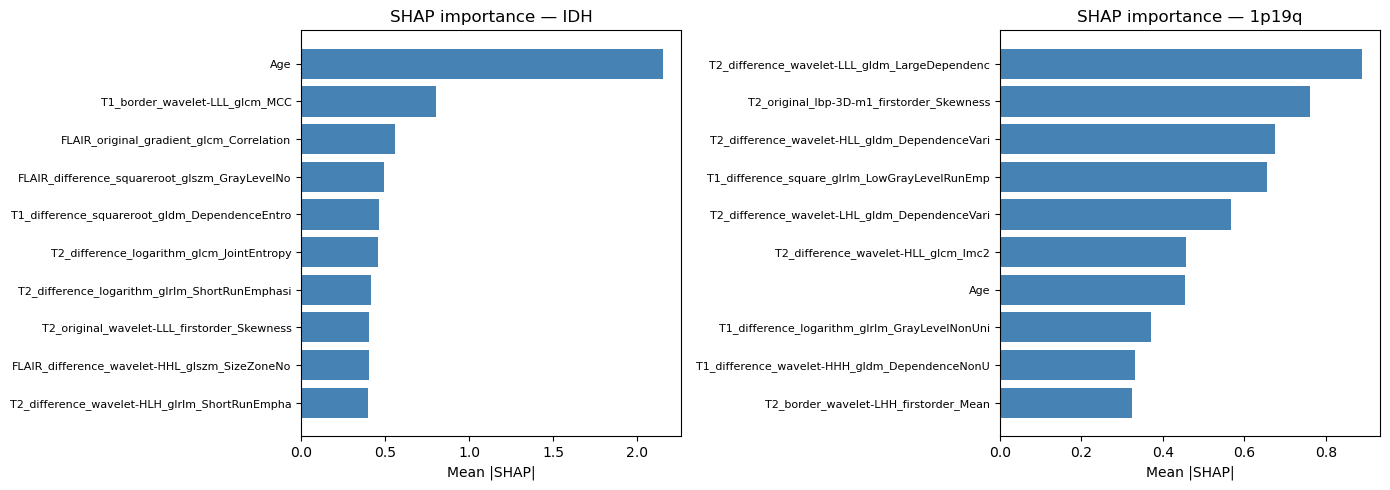

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, top, phi_mean, sel_feats, title in [
    (axes[0], top_idh, phi_idh, xgb_idh_feats, 'SHAP importance — IDH'),
    (axes[1], top_mrg, phi_mrg, xgb_mrg_feats, 'SHAP importance — 1p19q'),
]:
    # phi_mean is indexed over sel_feats (selected features), not all features
    feat_to_phi = {f: phi_mean[i] for i, f in enumerate(sel_feats)}
    vals = [feat_to_phi[f] for f in top]   # top is already top-k subset of sel_feats
    ax.barh(range(len(top)), vals[::-1], color='steelblue')
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([f[:45] for f in top[::-1]], fontsize=8)
    ax.set_xlabel('Mean |SHAP|')
    ax.set_title(title)
plt.tight_layout(); plt.show()


## 5 · ANFIS (GMM antecedents, zero-order Takagi-Sugeno)

In [33]:
class ANFISNet(nn.Module):
    """Zero-order ANFIS with diagonal Gaussian membership functions."""
    def __init__(self, centers, sigmas, consequents):
        super().__init__()
        self.centers     = nn.Parameter(torch.tensor(centers,     dtype=torch.float32))
        self.log_sigma   = nn.Parameter(torch.log(torch.tensor(sigmas, dtype=torch.float32) + 1e-8))
        self.consequents = nn.Parameter(torch.tensor(consequents, dtype=torch.float32))

    def forward(self, x):
        sigma = torch.exp(self.log_sigma)
        diff  = x[:,None,:] - self.centers[None,:,:]
        s     = -0.5*((diff/sigma)**2).sum(-1)
        w     = torch.softmax(s, dim=1)
        return w @ self.consequents


def fit_anfis(Xtr_df, ytr, Xte_df, yte, top_feats,
              K=K_RULES, epochs=300, lr=1e-3, wd=1e-4, seed=RANDOM_STATE):
    """
    Scale top features, fit GMM antecedents, train ANFIS.
    Class imbalance handled via:
      - GMM fit on class-balanced sample (duplicate minority rows)
      - Weighted consequent initialisation (per-rule, per-class)
      - Weighted CrossEntropyLoss during fine-tuning
    """
    ytr = np.asarray(ytr, int); yte = np.asarray(yte, int)
    C   = int(ytr.max()) + 1

    sc  = StandardScaler()
    Ztr = sc.fit_transform(Xtr_df[top_feats].values)
    Zte = sc.transform(Xte_df[top_feats].values)

    # drop near-constant dims
    keep = np.where(Ztr.std(0) >= 1e-12)[0]
    Ztr, Zte = Ztr[:,keep], Zte[:,keep]
    M = Ztr.shape[1]

    # ── class weights (inverse frequency) ────────────────────────────────────
    counts      = np.bincount(ytr, minlength=C).astype(float)
    cls_weights = len(ytr) / (C * np.maximum(counts, 1))          # (C,)
    sample_w    = cls_weights[ytr]                                  # (N,)
    ce_weights  = torch.tensor(cls_weights, dtype=torch.float32)   # for CrossEntropyLoss

    # ── GMM antecedents fit on class-balanced data ────────────────────────────
    # Oversample minority class so GMM sees balanced clusters
    max_n   = int(counts.max())
    idx_bal = []
    for c in range(C):
        idx_c = np.where(ytr == c)[0]
        idx_bal.append(np.random.RandomState(seed).choice(idx_c, max_n, replace=True))
    Ztr_bal = Ztr[np.concatenate(idx_bal)]

    cov = 'full' if M <= 12 else 'diag'
    gmm = GaussianMixture(n_components=K, covariance_type=cov,
                          n_init=5, reg_covar=1e-6, random_state=seed).fit(Ztr_bal)
    centers = gmm.means_.copy()
    sigmas  = (np.sqrt(gmm.covariances_) if cov=='diag'
               else np.sqrt(np.stack([np.diag(cv) for cv in gmm.covariances_])))

    # ── Weighted consequent init ──────────────────────────────────────────────
    # Rule memberships on original (imbalanced) train, but weighted by sample_w
    diff = Ztr[:,None,:] - centers[None,:,:]
    s    = -0.5*((diff/(sigmas+1e-12))**2).sum(2)
    W    = np.exp(s - s.max(1,keepdims=True)); W /= W.sum(1,keepdims=True)+1e-12
    B    = np.zeros((K, C))
    for k in range(K):
        wk = W[:,k] * sample_w                  # weight by inverse class freq
        den = wk.sum() + 1e-8
        for c in range(C):
            B[k,c] = (wk*(ytr==c)).sum() / den
    consequents = np.log(B + 1e-6)

    # ── Train ─────────────────────────────────────────────────────────────────
    model = ANFISNet(centers, sigmas, consequents)
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit  = nn.CrossEntropyLoss(weight=ce_weights)   # <── weighted loss

    Xt = torch.tensor(Ztr, dtype=torch.float32)
    yt = torch.tensor(ytr, dtype=torch.long)
    Xv = torch.tensor(Zte, dtype=torch.float32)

    for _ in range(epochs):
        model.train(); opt.zero_grad()
        loss = crit(model(Xt), yt)
        reg  = 1e-4*sum(p.pow(2).mean() for n,p in model.named_parameters()
                        if 'consequents' not in n)
        (loss+reg).backward(); opt.step()

    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(Xv), dim=1).numpy()

    m = compute_metrics(yte, proba[:,1])
    return proba[:,1], m, model, sc, centers, sigmas, top_feats


def anfis_cv(X, y, top_feats_per_fold_fn, label='ANFIS'):
    """CV: each fold runs XGB→SHAP top-k, then weighted ANFIS."""
    skf  = StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        Xtr, Xte = X.iloc[tr], X.iloc[te]
        ytr, yte = y.iloc[tr], y.iloc[te]

        # XGB → SHAP top-k on this fold
        _, _, booster, _ = run_xgb(Xtr, ytr, Xte, yte, label='')
        sel = make_selector(); sel.fit(Xtr, ytr.values)
        Xtr_s = sel.transform(Xtr)
        booster.feature_names = list(Xtr_s.columns)
        top, _, _ = shap_topk(booster, Xtr_s, ytr, TOP_K_SHAP)

        _, m, *_ = fit_anfis(Xtr, ytr.values, Xte, yte.values, top)
        m['fold'] = fold
        rows.append(m)
        print_metrics(m, f'  {label} fold {fold:2d}')
    summarise(rows, label)
    return rows


def print_anfis_rules(model, sc, centers, sigmas, top_feats, task_name,
                      class_names=('Class 0','Class 1'), top_features_per_rule=3):
    """
    Print interpretable IF-THEN rules extracted from a trained ANFIS.
    For each rule k:
      - firing prior  = mean firing strength over training data (from GMM geometry)
      - direction     = HIGH if center[k,j] > 0 in z-space (above mean), else LOW
      - saliency      = |center[k,j]| / sigma[k,j]  (how far the rule center is
                        from the feature mean in units of its own spread)
      - consequent    = softmax(B[k,:]) gives P(class | rule k fires)
    """
    import torch
    model.eval()

    centers_np = model.centers.detach().numpy()       # (K, M)
    sigmas_np  = torch.exp(model.log_sigma).detach().numpy()  # (K, M)
    conseq_np  = model.consequents.detach().numpy()   # (K, C)

    K, M = centers_np.shape
    C    = conseq_np.shape[1]

    # consequent probabilities per rule
    exp_b = np.exp(conseq_np - conseq_np.max(1, keepdims=True))
    probs = exp_b / exp_b.sum(1, keepdims=True)        # (K, C)

    # saliency: |z_center| / sigma  (how distinctive each feature is for this rule)
    saliency = np.abs(centers_np) / (sigmas_np + 1e-12)  # (K, M)

    print(f"\n{'═'*70}")
    print(f"  ANFIS Rules — {task_name}   ({K} rules, {M} features)")
    print(f"{'═'*70}")

    for k in range(K):
        pred_cls  = int(np.argmax(probs[k]))
        pred_p    = probs[k][pred_cls]
        cls_label = class_names[pred_cls] if pred_cls < len(class_names) else f'class {pred_cls}'

        # top features by saliency for this rule
        top_idx = np.argsort(-saliency[k])[:top_features_per_rule]

        print(f"\n  Rule {k+1:2d}  →  {cls_label}  (p={pred_p:.2f})")
        print(f"  {'─'*60}")
        print(f"  IF:")
        for j in top_idx:
            direction = 'HIGH' if centers_np[k, j] >= 0 else 'LOW '
            # map z-center back to original scale
            orig_val = centers_np[k, j] * sc.scale_[j] + sc.mean_[j]
            fname = top_feats[j]
            # shorten long radiomics names: keep last 3 underscore-parts
            short = '_'.join(fname.split('_')[-3:]) if fname.count('_') >= 3 else fname
            print(f"    {direction}  {short:<45s}  "
                  f"(z={centers_np[k,j]:+.2f}, val≈{orig_val:.3f}, sal={saliency[k,j]:.2f})")
        print(f"  THEN  {cls_label}  ", end='')
        for c in range(C):
            lbl = class_names[c] if c < len(class_names) else f'c{c}'
            print(f"P({lbl})={probs[k,c]:.2f}  ", end='')
        print()

    print(f"\n{'═'*70}\n")


In [34]:
print('ANFIS CV — IDH')
anfis_idh_cv = anfis_cv(Xtr_idh, ytr_idh, None, 'ANFIS-IDH')


ANFIS CV — IDH
                                 AUC=0.978  ACC=0.850  REC=0.714  SPEC=0.923  F1=0.769
    ANFIS-IDH fold  1            AUC=0.890  ACC=0.900  REC=0.929  SPEC=0.885  F1=0.867
                                 AUC=0.907  ACC=0.875  REC=0.786  SPEC=0.923  F1=0.815
    ANFIS-IDH fold  2            AUC=0.879  ACC=0.775  REC=0.714  SPEC=0.808  F1=0.690
                                 AUC=0.978  ACC=0.925  REC=0.929  SPEC=0.923  F1=0.897
    ANFIS-IDH fold  3            AUC=0.893  ACC=0.875  REC=0.857  SPEC=0.885  F1=0.828
                                 AUC=0.973  ACC=0.900  REC=0.786  SPEC=0.962  F1=0.846
    ANFIS-IDH fold  4            AUC=0.786  ACC=0.825  REC=0.643  SPEC=0.923  F1=0.720
                                 AUC=0.975  ACC=0.900  REC=0.929  SPEC=0.885  F1=0.867
    ANFIS-IDH fold  5            AUC=0.973  ACC=0.875  REC=0.714  SPEC=0.962  F1=0.800
                                 AUC=0.937  ACC=0.875  REC=0.692  SPEC=0.963  F1=0.783
    ANFIS-IDH fold  6       

In [35]:
print('ANFIS CV — Merged')
anfis_mrg_cv = anfis_cv(Xtr_mrg, ytr_mrg, None, 'ANFIS-MRG')


ANFIS CV — Merged
                                 AUC=0.694  ACC=0.643  REC=0.571  SPEC=0.714  F1=0.615
    ANFIS-MRG fold  1            AUC=0.765  ACC=0.571  REC=0.571  SPEC=0.571  F1=0.571
                                 AUC=0.952  ACC=0.769  REC=0.714  SPEC=0.833  F1=0.769
    ANFIS-MRG fold  2            AUC=0.952  ACC=0.923  REC=0.857  SPEC=1.000  F1=0.923
                                 AUC=0.905  ACC=0.769  REC=0.667  SPEC=0.857  F1=0.727
    ANFIS-MRG fold  3            AUC=0.690  ACC=0.615  REC=0.500  SPEC=0.714  F1=0.545
                                 AUC=0.857  ACC=0.846  REC=0.833  SPEC=0.857  F1=0.833
    ANFIS-MRG fold  4            AUC=0.881  ACC=0.846  REC=0.833  SPEC=0.857  F1=0.833
                                 AUC=0.738  ACC=0.769  REC=0.500  SPEC=1.000  F1=0.667
    ANFIS-MRG fold  5            AUC=0.857  ACC=0.692  REC=0.500  SPEC=0.857  F1=0.600
                                 AUC=0.929  ACC=0.846  REC=0.667  SPEC=1.000  F1=0.800
    ANFIS-MRG fold  6    

In [36]:
print('ANFIS test — IDH')
anfis_idh_proba, anfis_idh_m, anfis_idh_model, anfis_idh_sc, \
anfis_idh_centers, anfis_idh_sigmas, anfis_idh_top = fit_anfis(
    Xtr_idh, ytr_idh.values, Xte_idh, yte_idh.values, top_idh)
print_metrics(anfis_idh_m, 'ANFIS-IDH-test')
print_anfis_rules(anfis_idh_model, anfis_idh_sc, anfis_idh_centers,
                  anfis_idh_sigmas, anfis_idh_top,
                  task_name='IDH',
                  class_names=('IDH Wildtype', 'IDH Mutated'))

print()
print('ANFIS test — Merged (1p19q)')
anfis_mrg_proba, anfis_mrg_m, anfis_mrg_model, anfis_mrg_sc, \
anfis_mrg_centers, anfis_mrg_sigmas, anfis_mrg_top = fit_anfis(
    Xtr_mrg, ytr_mrg.values, Xte_mrg, yte_mrg.values, top_mrg)
print_metrics(anfis_mrg_m, 'ANFIS-MRG-test')
print_anfis_rules(anfis_mrg_model, anfis_mrg_sc, anfis_mrg_centers,
                  anfis_mrg_sigmas, anfis_mrg_top,
                  task_name='Merged 1p19q',
                  class_names=('1p19q non-deleted', '1p19q codeleted'))


ANFIS test — IDH
  ANFIS-IDH-test                 AUC=0.884  ACC=0.868  REC=0.900  SPEC=0.854  F1=0.800

══════════════════════════════════════════════════════════════════════
  ANFIS Rules — IDH   (10 rules, 10 features)
══════════════════════════════════════════════════════════════════════

  Rule  1  →  IDH Mutated  (p=0.73)
  ────────────────────────────────────────────────────────────
  IF:
    HIGH  squareroot_gldm_DependenceEntropy              (z=+1.31, val≈1.313, sal=1.96)
    LOW   Age                                            (z=-1.30, val≈-1.303, sal=1.80)
    HIGH  wavelet-HLH_glrlm_ShortRunEmphasis             (z=+0.58, val≈0.584, sal=1.56)
  THEN  IDH Mutated  P(IDH Wildtype)=0.27  P(IDH Mutated)=0.73  

  Rule  2  →  IDH Wildtype  (p=0.83)
  ────────────────────────────────────────────────────────────
  IF:
    LOW   squareroot_gldm_DependenceEntropy              (z=-0.87, val≈-0.871, sal=1.35)
    HIGH  Age                                            (z=+0.57, val≈0.57

## 6 · Bayesian Networks (HC+BIC and TAN)

In [37]:
# ── discretise ────────────────────────────────────────────────────────────────
def discretise(Xtr_df, Xte_df, n_bins=N_BINS):
    disc = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')
    Ztr  = pd.DataFrame(disc.fit_transform(Xtr_df), columns=Xtr_df.columns)
    Zte  = pd.DataFrame(disc.transform(Xte_df),     columns=Xte_df.columns)
    return Ztr.astype(int), Zte.astype(int)


# ── BN inference ──────────────────────────────────────────────────────────────
def bn_predict(model, X_disc, y_var='y'):
    infer  = VariableElimination(model)
    nodes  = set(model.nodes())
    cols   = [c for c in X_disc.columns if c in nodes and c != y_var]
    n_cls  = model.get_cpds(y_var).cardinality[0]
    proba  = np.full(len(X_disc), 0.5)
    for i, row in enumerate(X_disc[cols].itertuples(index=False)):
        ev = {c: int(v) for c, v in zip(cols, row)}
        try:
            q    = infer.query([y_var], evidence=ev, show_progress=False)
            vals = np.nan_to_num(q.values.astype(float))
            s    = vals.sum()
            if s > 0 and n_cls >= 2:
                proba[i] = vals[1]/s
        except Exception:
            pass
    return proba


# ── HC + BIC ──────────────────────────────────────────────────────────────────
def train_hc(Xtr_disc, ytr, y_var='y'):
    """
    Class imbalance: BDeu equivalent_sample_size (ESS) set proportional to
    minority-class ratio so the prior regularises minority class less harshly.
    """
    counts = np.bincount(ytr, minlength=2).astype(float)
    # ESS proportional to 2 * minority / majority  (range ~0.1 – 2)
    ess = max(0.1, 2.0 * counts.min() / max(counts.max(), 1))

    df = Xtr_disc.copy(); df[y_var] = ytr.astype(int)
    hc  = HillClimbSearch(df)
    dag = hc.estimate(scoring_method=BicScore(df))
    m   = BayesianNetwork(); m.add_nodes_from(df.columns); m.add_edges_from(dag.edges())
    m.fit(df, estimator=BayesianEstimator, prior_type='BDeu', equivalent_sample_size=ess)
    return m


# ── TAN ───────────────────────────────────────────────────────────────────────
def _cond_mi(df, xi, xj, yc):
    cmi, N = 0.0, len(df)
    for _, grp in df.groupby(yc):
        if len(grp) < 2: continue
        mi = mutual_info_classif(grp[[xi]], grp[xj],
                                  discrete_features=True, random_state=0)[0]
        cmi += (len(grp)/N)*float(mi)
    return cmi

def train_tan(Xtr_disc, ytr, y_var='y'):
    counts = np.bincount(ytr, minlength=2).astype(float)
    ess    = max(0.1, 2.0 * counts.min() / max(counts.max(), 1))

    df    = Xtr_disc.copy(); df[y_var] = ytr.astype(int)
    feats = list(Xtr_disc.columns)
    G = nx.Graph()
    G.add_nodes_from(feats)
    for i, xi in enumerate(feats):
        for xj in feats[i+1:]:
            G.add_edge(xi, xj, weight=_cond_mi(df, xi, xj, y_var))
    T    = nx.maximum_spanning_tree(G, weight='weight')
    mi_y = mutual_info_classif(df[feats], df[y_var], discrete_features=True, random_state=0)
    root = feats[int(np.argmax(mi_y))]
    edges = [(y_var, f) for f in feats] + list(nx.bfs_tree(T, source=root).edges())
    model = BayesianNetwork(); model.add_nodes_from([y_var]+feats); model.add_edges_from(edges)
    model.fit(df, estimator=BayesianEstimator, prior_type='BDeu', equivalent_sample_size=ess)
    return model


# ── BN runner (single fold or full-train) ─────────────────────────────────────
def run_bn(Xtr, ytr, Xte, yte, top_feats, label_prefix='BN'):
    Ztr, Zte = discretise(Xtr[top_feats], Xte[top_feats])
    ytr_a, yte_a = np.asarray(ytr,int), np.asarray(yte,int)

    try:
        m_hc = train_hc(Ztr, ytr_a)
        p_hc = bn_predict(m_hc, Zte)
        mh   = compute_metrics(yte_a, p_hc)
    except Exception as e:
        print(f'    HC failed: {e}')
        mh = {k: float('nan') for k in ['AUC','ACC','PREC','REC','SPEC','F1','BAL','BRIER']}
        p_hc = np.full(len(yte), 0.5); m_hc = None

    try:
        m_tan = train_tan(Ztr, ytr_a)
        p_tan = bn_predict(m_tan, Zte)
        mt    = compute_metrics(yte_a, p_tan)
    except Exception as e:
        print(f'    TAN failed: {e}')
        mt = {k: float('nan') for k in ['AUC','ACC','PREC','REC','SPEC','F1','BAL','BRIER']}
        p_tan = np.full(len(yte), 0.5); m_tan = None

    print_metrics(mh, f'{label_prefix} HC+BIC')
    print_metrics(mt, f'{label_prefix} TAN')
    return p_hc, mh, m_hc, p_tan, mt, m_tan


def bn_cv(X, y, label='BN'):
    skf  = StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    rows_hc, rows_tan = [], []
    for fold, (tr, te) in enumerate(skf.split(X, y), 1):
        Xtr, Xte = X.iloc[tr], X.iloc[te]
        ytr, yte = y.iloc[tr], y.iloc[te]
        # XGB → SHAP top-k
        _, _, booster, _ = run_xgb(Xtr, ytr, Xte, yte, label='')
        sel = make_selector(); sel.fit(Xtr, ytr.values)
        Xtr_s = sel.transform(Xtr)
        booster.feature_names = list(Xtr_s.columns)
        top, _, _ = shap_topk(booster, Xtr_s, ytr, TOP_K_SHAP)

        print(f'  fold {fold:2d}', end='  ')
        _, mh, _, _, mt, _ = run_bn(Xtr, ytr.values, Xte, yte.values, top, label_prefix='')
        mh['fold'] = fold; rows_hc.append(mh)
        mt['fold'] = fold; rows_tan.append(mt)

    summarise(rows_hc,  f'{label} HC+BIC')
    summarise(rows_tan, f'{label} TAN')
    return rows_hc, rows_tan


In [38]:
print('BN CV — IDH')
bn_idh_hc_cv, bn_idh_tan_cv = bn_cv(Xtr_idh, ytr_idh, 'BN-IDH')


BN CV — IDH
                                 AUC=0.978  ACC=0.850  REC=0.714  SPEC=0.923  F1=0.769
  fold  1  

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.871  ACC=0.800  REC=0.643  SPEC=0.885  F1=0.692
   TAN                           AUC=0.865  ACC=0.825  REC=0.643  SPEC=0.923  F1=0.720
                                 AUC=0.907  ACC=0.875  REC=0.786  SPEC=0.923  F1=0.815
  fold  2  

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.835  ACC=0.775  REC=0.714  SPEC=0.808  F1=0.690
   TAN                           AUC=0.742  ACC=0.725  REC=0.571  SPEC=0.808  F1=0.593
                                 AUC=0.978  ACC=0.925  REC=0.929  SPEC=0.923  F1=0.897
  fold  3  

  0%|          | 0/1000000 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.912  ACC=0.900  REC=0.846  SPEC=0.926  F1=0.846
   TAN                           AUC=0.897  ACC=0.775  REC=0.692  SPEC=0.815  F1=0.667
                                 AUC=0.923  ACC=0.846  REC=0.769  SPEC=0.885  F1=0.769
  fold 10  

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.867  ACC=0.795  REC=0.615  SPEC=0.885  F1=0.667
   TAN                           AUC=0.976  ACC=0.846  REC=0.538  SPEC=1.000  F1=0.700

  ────────────────────────────────────────────────────
  BN-IDH HC+BIC — mean ± std  (n=10 folds)
  ────────────────────────────────────────────────────
  AUC   : 0.8936 ± 0.0534
  ACC   : 0.8470 ± 0.0644
  REC   : 0.7269 ± 0.1013
  SPEC  : 0.9085 ± 0.0659
  F1    : 0.7639 ± 0.0938
  BAL   : 0.8177 ± 0.0686
  BRIER : 0.1188 ± 0.0431

  ────────────────────────────────────────────────────
  BN-IDH TAN — mean ± std  (n=10 folds)
  ────────────────────────────────────────────────────
  AUC   : 0.8412 ± 0.0787
  ACC   : 0.7846 ± 0.0438
  REC   : 0.6071 ± 0.0508
  SPEC  : 0.8756 ± 0.0753
  F1    : 0.6580 ± 0.0515
  BAL   : 0.7414 ± 0.0349
  BRIER : 0.1778 ± 0.0435


In [39]:
print('BN CV — Merged')
bn_mrg_hc_cv, bn_mrg_tan_cv = bn_cv(Xtr_mrg, ytr_mrg, 'BN-MRG')


BN CV — Merged
                                 AUC=0.694  ACC=0.643  REC=0.571  SPEC=0.714  F1=0.615
  fold  1  

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.694  ACC=0.643  REC=0.857  SPEC=0.429  F1=0.706
   TAN                           AUC=0.633  ACC=0.571  REC=0.429  SPEC=0.714  F1=0.500
                                 AUC=0.952  ACC=0.769  REC=0.714  SPEC=0.833  F1=0.769
  fold  2  

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.845  ACC=0.846  REC=0.714  SPEC=1.000  F1=0.833
   TAN                           AUC=0.929  ACC=0.846  REC=0.714  SPEC=1.000  F1=0.833
                                 AUC=0.905  ACC=0.769  REC=0.667  SPEC=0.857  F1=0.727
  fold  3  

  0%|          | 0/1000000 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=0.833  ACC=0.846  REC=1.000  SPEC=0.714  F1=0.857
   TAN                           AUC=0.738  ACC=0.615  REC=0.667  SPEC=0.571  F1=0.615
                                 AUC=0.976  ACC=0.923  REC=1.000  SPEC=0.857  F1=0.923
  fold 10  

  0%|          | 0/1000000 [00:00<?, ?it/s]

   HC+BIC                        AUC=1.000  ACC=0.923  REC=1.000  SPEC=0.857  F1=0.923
   TAN                           AUC=0.929  ACC=0.846  REC=0.833  SPEC=0.857  F1=0.833

  ────────────────────────────────────────────────────
  BN-MRG HC+BIC — mean ± std  (n=10 folds)
  ────────────────────────────────────────────────────
  AUC   : 0.8587 ± 0.0970
  ACC   : 0.7951 ± 0.0909
  REC   : 0.8571 ± 0.1397
  SPEC  : 0.7429 ± 0.1756
  F1    : 0.7981 ± 0.0832
  BAL   : 0.8000 ± 0.0929
  BRIER : 0.1591 ± 0.0655

  ────────────────────────────────────────────────────
  BN-MRG TAN — mean ± std  (n=10 folds)
  ────────────────────────────────────────────────────
  AUC   : 0.7906 ± 0.1594
  ACC   : 0.7033 ± 0.1339
  REC   : 0.5976 ± 0.1292
  SPEC  : 0.8000 ± 0.1928
  F1    : 0.6583 ± 0.1366
  BAL   : 0.6988 ± 0.1323
  BRIER : 0.2560 ± 0.1135


In [40]:
print('BN test — IDH')
bn_idh_hc_p, bn_idh_hc_m, bn_idh_hc_model, \
bn_idh_tan_p, bn_idh_tan_m, bn_idh_tan_model = run_bn(
    Xtr_idh, ytr_idh.values, Xte_idh, yte_idh.values, top_idh, 'BN-IDH')

print()
print('BN test — Merged')
bn_mrg_hc_p, bn_mrg_hc_m, bn_mrg_hc_model, \
bn_mrg_tan_p, bn_mrg_tan_m, bn_mrg_tan_model = run_bn(
    Xtr_mrg, ytr_mrg.values, Xte_mrg, yte_mrg.values, top_mrg, 'BN-MRG')


BN test — IDH


  0%|          | 0/1000000 [00:00<?, ?it/s]

  BN-IDH HC+BIC                  AUC=0.933  ACC=0.882  REC=0.750  SPEC=0.938  F1=0.789
  BN-IDH TAN                     AUC=0.917  ACC=0.868  REC=0.850  SPEC=0.875  F1=0.791

BN test — Merged


  0%|          | 0/1000000 [00:00<?, ?it/s]

  BN-MRG HC+BIC                  AUC=0.844  ACC=0.778  REC=0.727  SPEC=0.857  F1=0.800
  BN-MRG TAN                     AUC=0.844  ACC=0.722  REC=0.636  SPEC=0.857  F1=0.737


## 7 · Results Summary & Plots

In [41]:
# ── Metrics table ─────────────────────────────────────────────────────────────
def results_table(task, xgb_m, anfis_m, hc_m, tan_m):
    rows = [('XGB',     xgb_m),
            ('ANFIS',   anfis_m),
            ('BN HC+BIC', hc_m),
            ('BN TAN',  tan_m)]
    df = pd.DataFrame(
        [{**{'Model':n}, **{k:round(v,4) for k,v in m.items()}} for n,m in rows]
    ).set_index('Model')
    print(f'\n── Test results: {task} ──')
    print(df[['AUC','ACC','REC','SPEC','F1','BAL','BRIER']].to_string())
    return df

tbl_idh = results_table('IDH',    xgb_idh_m, anfis_idh_m, bn_idh_hc_m, bn_idh_tan_m)
tbl_mrg = results_table('Merged', xgb_mrg_m, anfis_mrg_m, bn_mrg_hc_m, bn_mrg_tan_m)



── Test results: IDH ──
              AUC     ACC   REC    SPEC      F1     BAL   BRIER
Model                                                          
XGB        0.9500  0.8971  0.80  0.9375  0.8205  0.8688  0.0861
ANFIS      0.8844  0.8676  0.90  0.8542  0.8000  0.8771  0.1219
BN HC+BIC  0.9333  0.8824  0.75  0.9375  0.7895  0.8438  0.0974
BN TAN     0.9167  0.8676  0.85  0.8750  0.7907  0.8625  0.1011

── Test results: Merged ──
              AUC     ACC     REC    SPEC      F1     BAL   BRIER
Model                                                            
XGB        0.8701  0.7778  0.7273  0.8571  0.8000  0.7922  0.1727
ANFIS      0.7922  0.7778  0.8182  0.7143  0.8182  0.7662  0.1910
BN HC+BIC  0.8442  0.7778  0.7273  0.8571  0.8000  0.7922  0.2092
BN TAN     0.8442  0.7222  0.6364  0.8571  0.7368  0.7468  0.2479


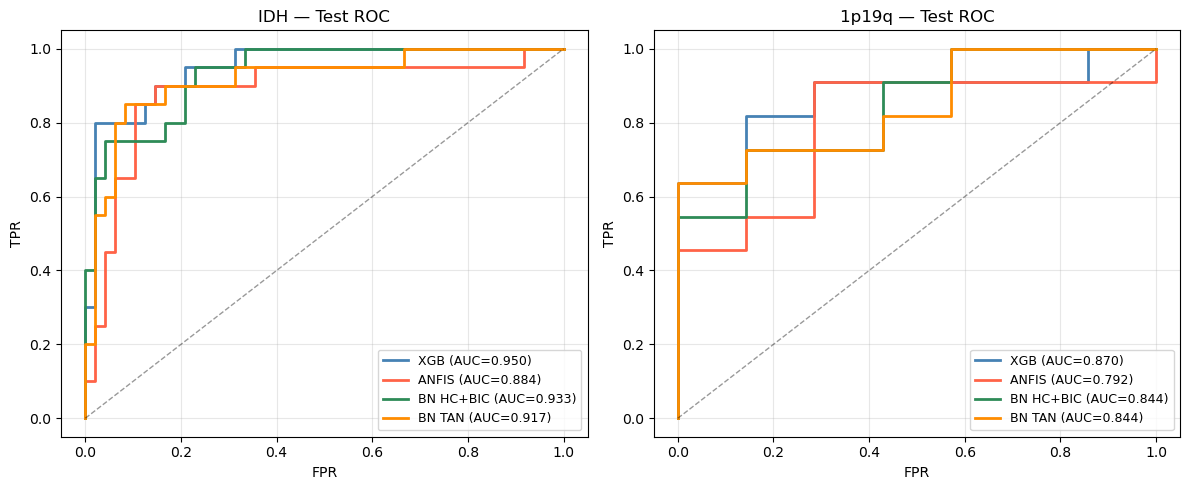

In [42]:
# ── ROC curves ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = {'XGB':'steelblue','ANFIS':'tomato','BN HC+BIC':'seagreen','BN TAN':'darkorange'}

for ax, (yte, probas, title) in zip(axes, [
    (yte_idh, {'XGB':xgb_idh_proba,'ANFIS':anfis_idh_proba,
               'BN HC+BIC':bn_idh_hc_p,'BN TAN':bn_idh_tan_p}, 'IDH — Test ROC'),
    (yte_mrg, {'XGB':xgb_mrg_proba,'ANFIS':anfis_mrg_proba,
               'BN HC+BIC':bn_mrg_hc_p,'BN TAN':bn_mrg_tan_p}, '1p19q — Test ROC'),
]):
    for name, p in probas.items():
        plot_roc(ax, yte, p, name, colors[name])
    ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
    ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title(title); ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()


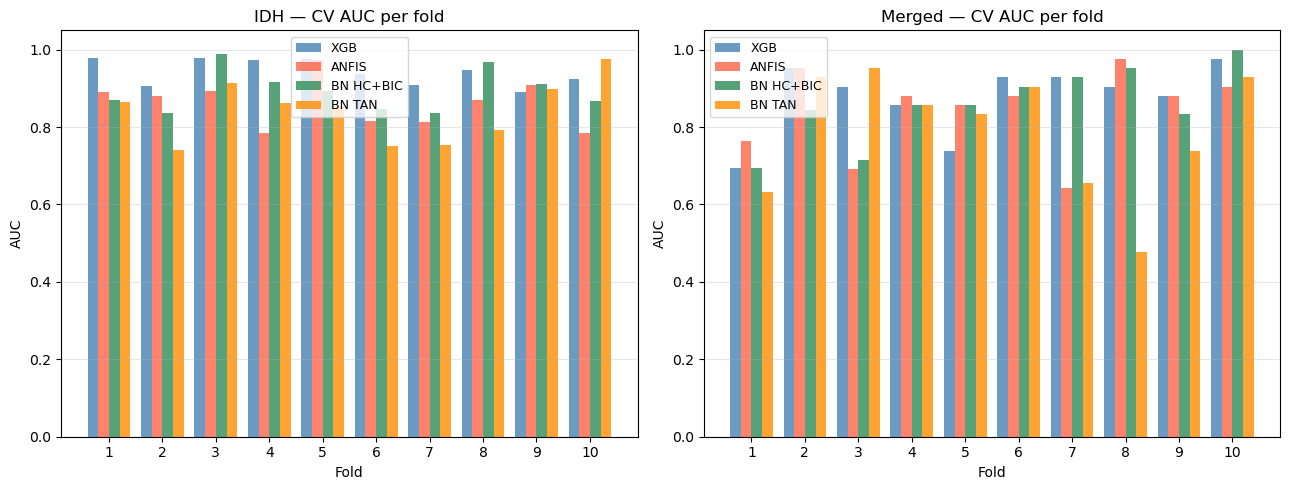

In [43]:
# ── CV AUC comparison bar chart ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (xgb_cv, anfis_cv_, hc_cv, tan_cv, title) in zip(axes, [
    (xgb_idh_cv,  anfis_idh_cv, bn_idh_hc_cv, bn_idh_tan_cv, 'IDH — CV AUC per fold'),
    (xgb_mrg_cv,  anfis_mrg_cv, bn_mrg_hc_cv, bn_mrg_tan_cv, 'Merged — CV AUC per fold'),
]):
    folds = np.arange(1, N_SPLITS+1)
    w     = 0.2
    for i, (cv, name, color) in enumerate([
        (xgb_cv,   'XGB',      'steelblue'),
        (anfis_cv_,'ANFIS',    'tomato'),
        (hc_cv,    'BN HC+BIC','seagreen'),
        (tan_cv,   'BN TAN',   'darkorange'),
    ]):
        aucs = [r['AUC'] for r in cv]
        ax.bar(folds + (i-1.5)*w, aucs, width=w, label=name, color=color, alpha=0.8)
    ax.set_xticks(folds); ax.set_xlabel('Fold'); ax.set_ylabel('AUC')
    ax.set_ylim(0, 1.05); ax.set_title(title)
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)

plt.tight_layout(); plt.show()


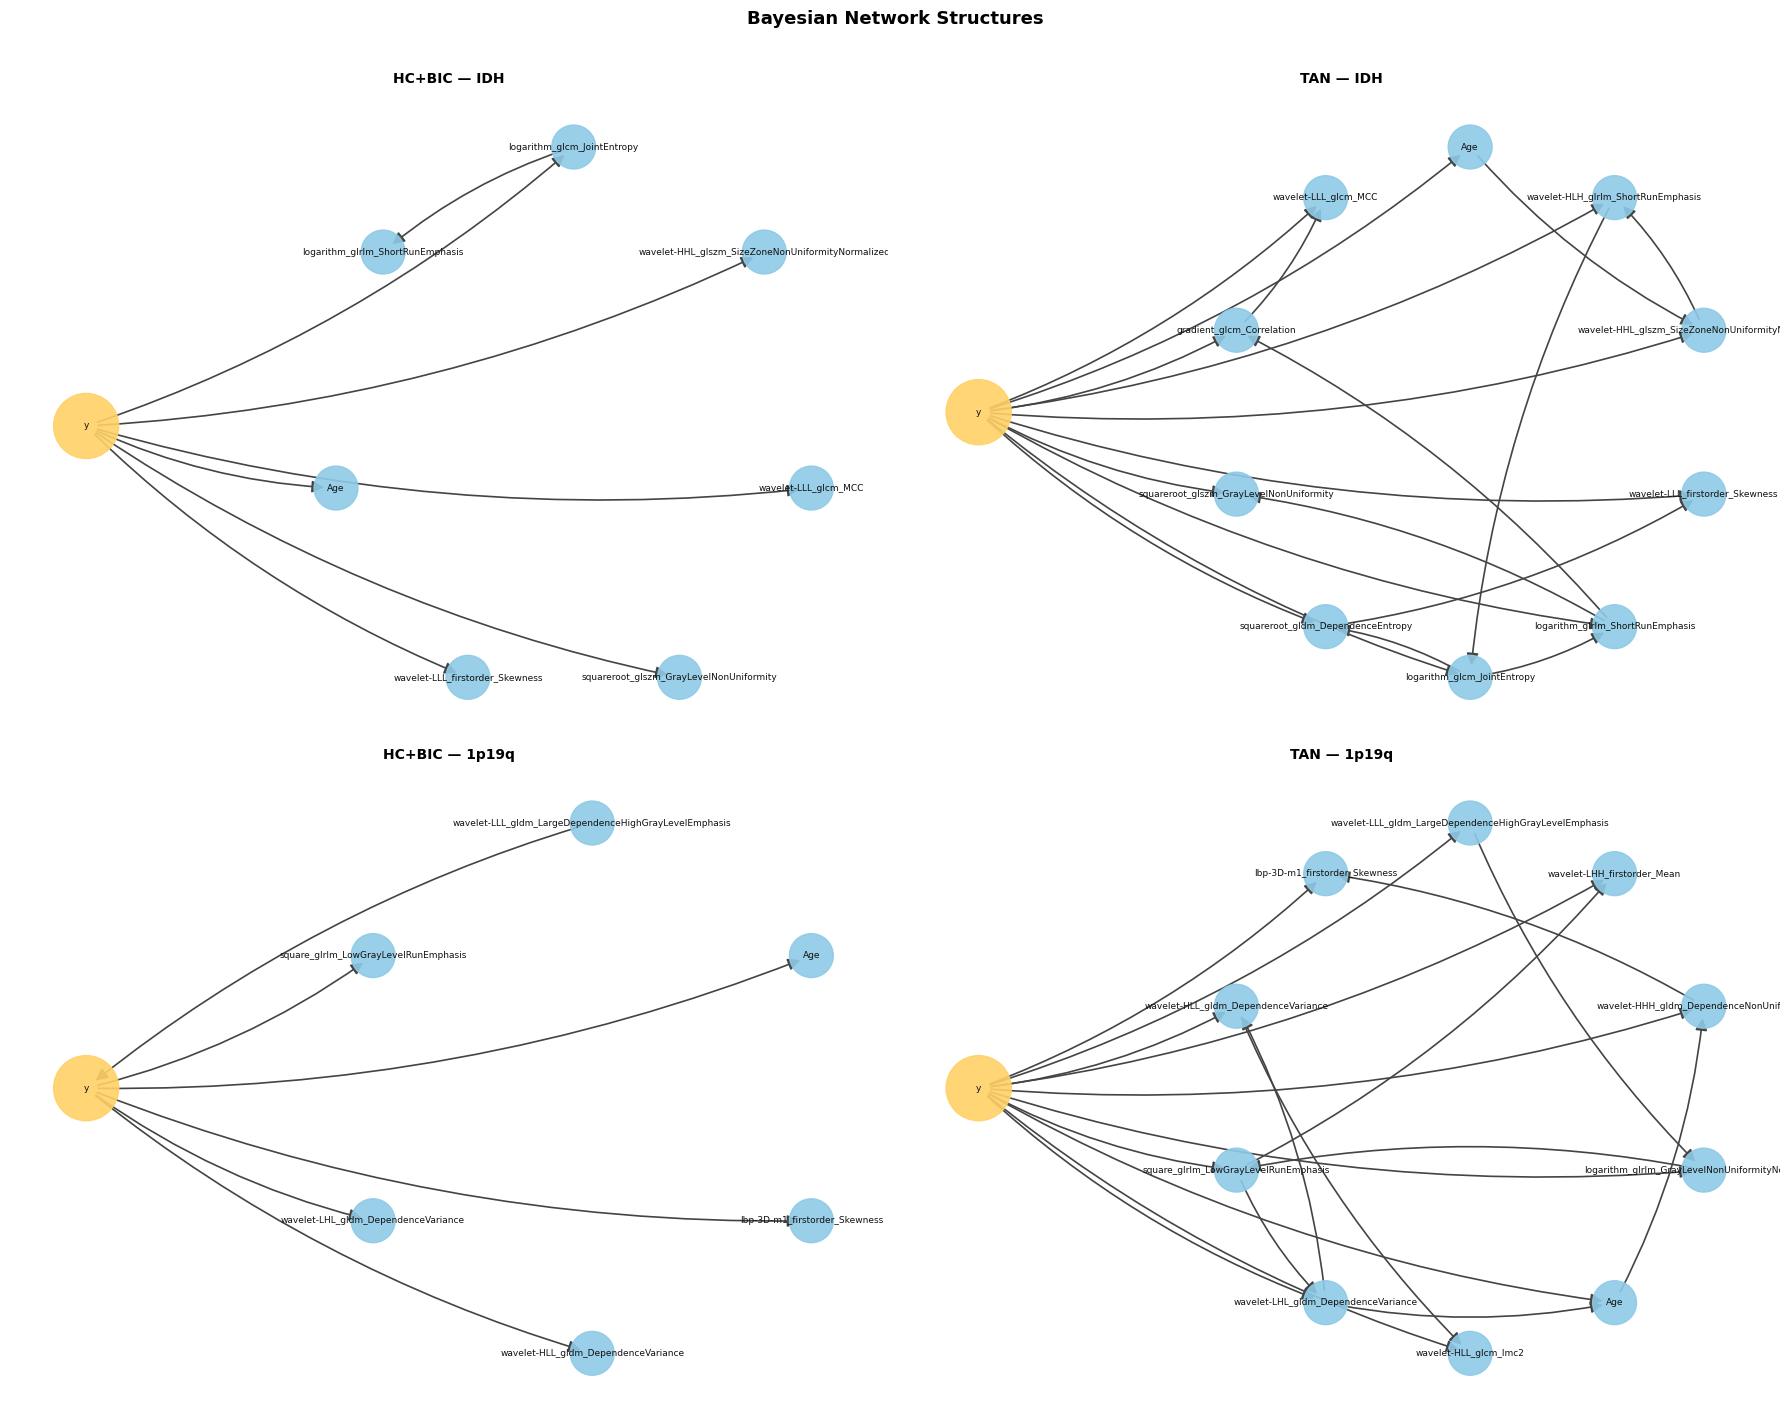

In [44]:
def plot_bn_graph(ax, model, title, class_label='y'):
    """
    Draw a BN DAG with:
      - shell layout so the class node sits in the centre and features fan out
      - node labels shortened to last 3 underscore-parts
      - edge weights proportional to saliency (not available here, uniform)
      - larger figure separation via k parameter in spring fallback
    """
    if model is None:
        ax.text(0.5, 0.5, 'Model not available', ha='center', va='center',
                transform=ax.transAxes, fontsize=11)
        ax.set_title(title); return

    G    = nx.DiGraph(list(model.edges()))
    nodes = list(G.nodes())

    # shorten names
    def short(n):
        if n == class_label: return n
        parts = n.split('_')
        return '_'.join(parts[-3:]) if len(parts) >= 3 else n

    label_map = {n: short(n) for n in nodes}

    # layout: class node at centre, all others in a circle around it
    feat_nodes = [n for n in nodes if n != class_label]
    if class_label in nodes:
        shells = [feat_nodes, [class_label]]
    else:
        shells = [feat_nodes]
    try:
        pos = nx.shell_layout(G, nlist=shells)
    except Exception:
        pos = nx.spring_layout(G, seed=42, k=3.0)

    # scale positions further apart
    import numpy as np
    if pos:
        all_pos = np.array(list(pos.values()))
        spread  = all_pos.std(0).mean()
        if spread > 0:
            center = all_pos.mean(0)
            for n in pos:
                pos[n] = (pos[n] - center) * 2.5 + center

    node_colors = ['#ffd166' if n == class_label else '#8ecae6' for n in nodes]
    node_sizes  = [2200 if n == class_label else 1000 for n in nodes]

    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                           node_size=node_sizes, alpha=0.9)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowsize=18,
                           edge_color='#444', width=1.2,
                           connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, ax=ax, labels=label_map,
                            font_size=6.5, font_color='#111')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.axis('off')


fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Bayesian Network Structures', fontsize=13, fontweight='bold', y=1.01)

plot_bn_graph(axes[0,0], bn_idh_hc_model,  'HC+BIC — IDH')
plot_bn_graph(axes[0,1], bn_idh_tan_model,  'TAN — IDH')
plot_bn_graph(axes[1,0], bn_mrg_hc_model,   'HC+BIC — 1p19q')
plot_bn_graph(axes[1,1], bn_mrg_tan_model,  'TAN — 1p19q')

plt.tight_layout()
plt.show()
